In [2]:
import pandas as pd
url=("https://earthquake.usgs.gov/fdsnws/event/1/query"
    "?format=csv"
    "&starttime=2026-09-10T00:00:00"
    "&endtime=2026-10-10T23:59:59"
    "&minmagnitude=2.5"
    "&orderby=time-asc"
    "&limit=20000")
df=pd.read_csv(url)
print(df.shape)
print(df.head())

(1884, 22)
                       time   latitude   longitude     depth   mag magType  \
0  2026-09-10T00:15:33.655Z  31.640000 -104.408000    6.3306  3.00      ml   
1  2026-09-10T01:24:04.400Z  40.289333 -124.516333   20.3400  3.79      mw   
2  2026-09-10T01:24:48.040Z  40.290833 -124.531833   20.4400  3.63      mw   
3  2026-09-10T01:57:36.656Z -21.004000  -69.222200  119.7040  4.30      mb   
4  2026-09-10T02:22:11.219Z  63.511000 -151.407000    5.0000  3.60      ml   

   nst  gap    dmin   rms  ...                   updated  \
0   43   72  0.0000  0.20  ...  2026-10-01T05:25:38.040Z   
1   52  249  0.1329  0.18  ...  2026-10-06T05:50:55.040Z   
2   55  236  0.1448  0.18  ...  2026-10-06T05:35:22.040Z   
3   24   67  0.7030  0.91  ...  2026-10-06T05:24:56.040Z   
4  159   27  0.2000  1.40  ...  2026-10-06T05:20:25.040Z   

                                       place        type horizontalError  \
0         59 km S of Whites City, New Mexico  earthquake        1.076538   
1      

In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1884 entries, 0 to 1883
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             1884 non-null   object 
 1   latitude         1884 non-null   float64
 2   longitude        1884 non-null   float64
 3   depth            1884 non-null   float64
 4   mag              1884 non-null   float64
 5   magType          1884 non-null   object 
 6   nst              1884 non-null   int64  
 7   gap              1884 non-null   int64  
 8   dmin             1883 non-null   float64
 9   rms              1884 non-null   float64
 10  net              1884 non-null   object 
 11  id               1884 non-null   object 
 12  updated          1884 non-null   object 
 13  place            1884 non-null   object 
 14  type             1884 non-null   object 
 15  horizontalError  1860 non-null   float64
 16  depthError       1878 non-null   float64
 17  magError      

In [4]:
print(df.isna().sum())

time                0
latitude            0
longitude           0
depth               0
mag                 0
magType             0
nst                 0
gap                 0
dmin                1
rms                 0
net                 0
id                  0
updated             0
place               0
type                0
horizontalError    24
depthError          6
magError           16
magNst              7
status              0
locationSource      0
magSource           0
dtype: int64


In [9]:
df["time"]=pd.to_datetime(df["time"],utc=True)
print(df["time"].dtype)

datetime64[ns, UTC]


In [11]:
df["date"]=df["time"].dt.date
print(df["date"])

0       2026-09-10
1       2026-09-10
2       2026-09-10
3       2026-09-10
4       2026-09-10
           ...    
1879    2026-10-10
1880    2026-10-10
1881    2026-10-10
1882    2026-10-10
1883    2026-10-10
Name: date, Length: 1884, dtype: object


In [12]:
daily_counts = df["date"].value_counts().sort_index()

print(daily_counts)

date
2026-09-10    65
2026-09-11    78
2026-09-12    88
2026-09-13    65
2026-09-14    65
2026-09-15    74
2026-09-16    71
2026-09-17    62
2026-09-18    86
2026-09-19    60
2026-09-20    74
2026-09-21    69
2026-09-22    64
2026-09-23    69
2026-09-24    56
2026-09-25    56
2026-09-26    66
2026-09-27    74
2026-09-28    78
2026-09-29    57
2026-09-30    46
2026-10-01    44
2026-10-02    44
2026-10-03    42
2026-10-04    45
2026-10-05    44
2026-10-06    61
2026-10-07    41
2026-10-08    35
2026-10-09    64
2026-10-10    41
Name: count, dtype: int64


In [13]:
largest=df.loc[df["mag"].idxmax()]
print("Magnitude:", largest["mag"])
print("Depth (km):", largest["depth"])
print("Location:", largest["place"])
print("Time:", largest["time"])

Magnitude: 7.7
Depth (km): 12.647
Location: 12 km WSW of Pitaloza Arriba, Panama
Time: 2026-10-09 17:56:06.036000+00:00


In [14]:
print("Average magnitude:", df["mag"].mean())
print("Median magnitude:", df["mag"].median())
print("Average depth (km):", df["depth"].mean())
print("Shallowest depth (km):", df["depth"].min())
print("Deepest depth (km):", df["depth"].max())

Average magnitude: 3.773133825942089
Median magnitude: 4.0
Average depth (km): 56.03312924656924
Shallowest depth (km): -3.43
Deepest depth (km): 665.057


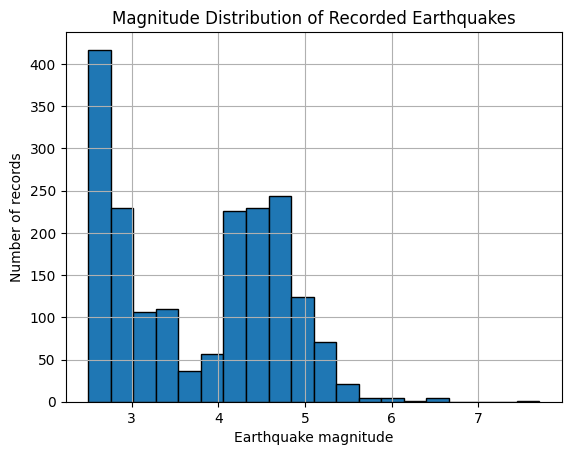

In [17]:
import matplotlib.pyplot as plt
df["mag"].hist(bins=20,edgecolor="black")
plt.xlabel("Earthquake magnitude")
plt.ylabel("Number of records")
plt.title("Magnitude Distribution of Recorded Earthquakes")
plt.show()

In [18]:
small=(df["mag"]<4).sum()
moderate=((df["mag"]>=4)&(df["mag"]<6)).sum()
large=(df["mag"]>=6).sum()
print("Small: ",small)
print("Moderate: ",moderate)
print("Large: ",large)

Small:  925
Moderate:  951
Large:  8


In [19]:
print(small+moderate+large)
print(len(df))

1884
1884


In [20]:
per=(large/len(df))*100
print(per)

0.42462845010615713


In [21]:
deep=df[df["depth"]>300]
print("Earthquakes deeper than 300 km: ",len(deep))
print((deep[["mag","depth","place"]].head(10)))

Earthquakes deeper than 300 km:  66
     mag    depth                                    place
8    4.1  573.156                              Fiji region
18   4.3  451.154          179 km WNW of Manado, Indonesia
29   4.8  371.070                38 km S of Cliza, Bolivia
137  6.5  372.000       121 km NNE of Teluknaga, Indonesia
199  4.0  580.657                              Fiji region
201  4.3  301.453            Kermadec Islands, New Zealand
203  4.4  314.198     108 km NW of Arawa, Papua New Guinea
208  4.3  393.797  126 km WNW of Panguna, Papua New Guinea
225  4.3  368.234    93 km NNE of Rabaul, Papua New Guinea
231  4.1  363.296                23 km ENE of Owase, Japan


In [23]:
shallow=df[df["depth"]<70]
deep=df[df["depth"]>300]

print("Shallow count:",len(shallow))
print("Shallow average magnitude: ",shallow["mag"].mean())
print("Deep count:",len(deep))
print("Deep average magnitude: ",deep["mag"].mean())

Shallow count: 1450
Shallow average magnitude:  3.7172028469482044
Deep count: 66
Deep average magnitude:  4.407575757575759


In [25]:
correlation=df["depth"].corr(df["mag"])
print(correlation)

0.15193795305304048


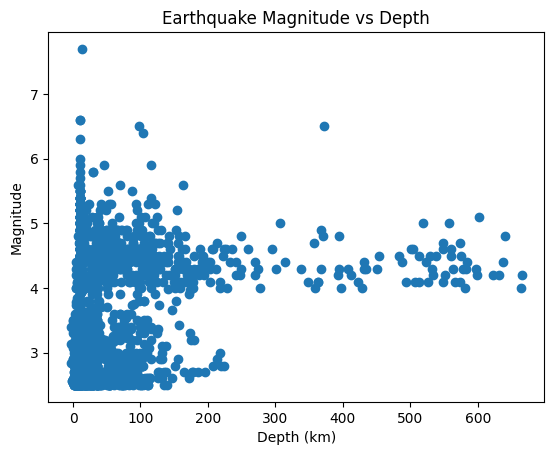

In [26]:
import matplotlib.pyplot as plt

plt.scatter(df["depth"],df["mag"])
plt.xlabel("Depth (km)")
plt.ylabel("Magnitude")
plt.title("Earthquake Magnitude vs Depth")
plt.show()

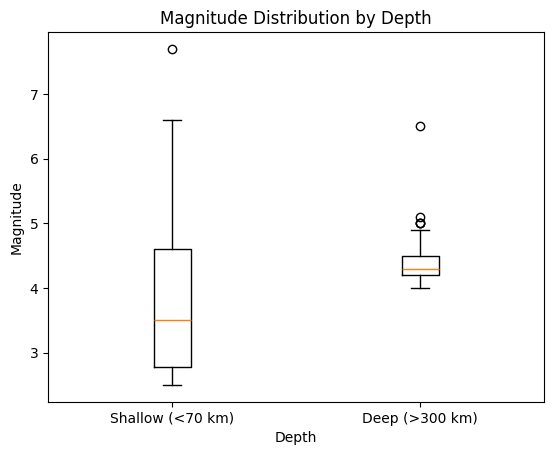

In [28]:
plt.boxplot([shallow["mag"].dropna(), deep["mag"].dropna()],tick_labels=["Shallow (<70 km)","Deep (>300 km)"])
plt.xlabel("Depth")
plt.ylabel("Magnitude")
plt.title("Magnitude Distribution by Depth")
plt.show()

In [29]:
shallow_median=shallow["mag"].median()
deep_median=deep["mag"].median()

print("Shallow median:", shallow_median)
print("Deep median:", deep_median)
print("Difference:", deep_median - shallow_median)

Shallow median: 3.5
Deep median: 4.3
Differnce: 0.7999999999999998


In [30]:
intermediate=df[(df["depth"]>=70)&(df["depth"]<=300)]
print("Intermediate count:",len(intermediate))
print("Intermediate median magnitude:",intermediate["mag"].median())

Intermediate count: 368
Intermediate median magnitude: 4.2


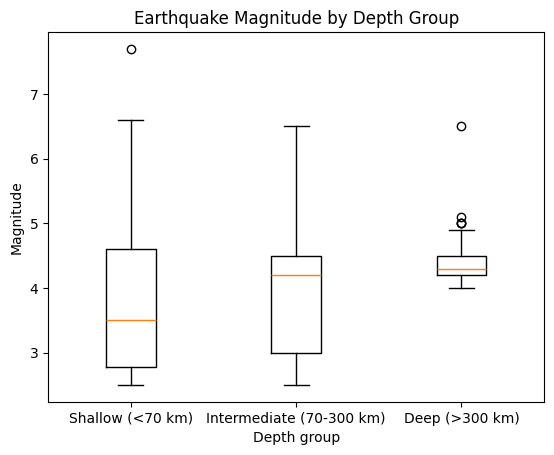

In [33]:
plt.boxplot([shallow["mag"].dropna(), intermediate["mag"].dropna(), deep["mag"].dropna()],tick_labels=["Shallow (<70 km)","Intermediate (70-300 km)","Deep (>300 km)"])
plt.xlabel("Depth group")
plt.ylabel("Magnitude")
plt.title("Earthquake Magnitude by Depth Group")
plt.show()

In [34]:
summary=pd.DataFrame({"Depth group": ["Shallow", "Intermediate", "Deep"],
                      "Count": [len(shallow),len(intermediate),len(deep)],
                      "Median magnitude": [shallow["mag"].median(), intermediate["mag"].median(), deep["mag"].median()]
                      })
print(summary)
summary.to_csv("earthquake_depth_summary.csv", index=False)

    Depth froup  Count  Median magnitude
0       Shallow   1450               3.5
1  Intermediate    368               4.2
2          Deep     66               4.3


In [35]:
print(summary)
print(summary.shape)

    Depth froup  Count  Median magnitude
0       Shallow   1450               3.5
1  Intermediate    368               4.2
2          Deep     66               4.3
(3, 3)
